# **Task-01**

**Mounting Google Drive in Google Colab**

In [1]:
import os

folder_path = "/content/drive/MyDrive/Datasets_Assignment"

os.makedirs(folder_path, exist_ok=True)

print("Folder created successfully!")

Folder created successfully!


**Importing the Kaggle Dataset**

In [2]:
!pip install -q kaggle

In [3]:
import os

os.environ["KAGGLE_API_TOKEN"] = "KGAT_c4ccf1aa4a21774cef165da322141fb6"

In [4]:
os.environ["KAGGLE_USERNAME"] = "gayatribhakta"

In [5]:
!kaggle datasets download -d developerghost/climate-in-india-daily-weather-data-2000-2024

Dataset URL: https://www.kaggle.com/datasets/developerghost/climate-in-india-daily-weather-data-2000-2024
License(s): MIT
100% 1.44M/1.44M [00:00<00:00, 139MB/s]



In [6]:
!unzip -o climate-in-india-daily-weather-data-2000-2024.zip


Archive:  climate-in-india-daily-weather-data-2000-2024.zip
  inflating: india_2000_2024_daily_weather.csv  


In [7]:
import os

print(os.listdir('/content'))

['.config', 'climate-in-india-daily-weather-data-2000-2024.zip', 'india_2000_2024_daily_weather.csv', 'drive', 'sample_data']


In [8]:
import shutil

source = "/content/india_2000_2024_daily_weather.csv"
destination = "/content/drive/MyDrive/Datasets_Assignment/india_2000_2024_daily_weather.csv"

shutil.copy(source, destination)

print("✅ Dataset copied successfully to Google Drive!")

✅ Dataset copied successfully to Google Drive!


In [9]:
import pandas as pd

weather_df = pd.read_csv(
    "/content/drive/MyDrive/Datasets_Assignment/india_2000_2024_daily_weather.csv"
)

weather_df.head() #the he first five rows is displayed

,city,date,temperature_2m_max,temperature_2m_min,apparent_temperature_max,apparent_temperature_min,precipitation_sum,rain_sum,weather_code,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant
0,Delhi,2000-01-01,19.9,7.4,19.2,5.8,0.0,0.0,0,10.9,13.3,58
1,Delhi,2000-01-02,20.0,5.5,18.9,3.4,0.0,0.0,3,9.5,14.8,326
2,Delhi,2000-01-03,20.1,6.3,18.2,4.3,0.0,0.0,0,10.0,23.8,309
3,Delhi,2000-01-04,19.8,6.4,18.5,4.2,0.0,0.0,0,8.6,18.7,311
4,Delhi,2000-01-05,19.4,5.3,17.7,3.2,0.0,0.0,0,9.4,20.2,322


Importing the hugging face dataset

In [10]:
!pip install -q datasets

In [11]:
from datasets import load_dataset

dataset = load_dataset("infinite-dataset-hub/MonsoonImpactStudy")

print(dataset)

README.md:   0%|          | 0.00/2.04k [00:00<?, ?B/s]

data.csv:   0%|          | 0.00/7.59k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/91 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['idx', 'Date', 'Region', 'Temperature (°C)', 'Rainfall (mm)', 'Humidity (%)', 'Wind Speed (km/h)', 'Agricultural Productivity Index', 'Sustainable Development Index', 'Monsoon Prediction Accuracy', 'Label'],
        num_rows: 91
    })
})


In [12]:
import pandas as pd

monsoon_df = dataset["train"].to_pandas()

monsoon_df.head()

,idx,Date,Region,Temperature (°C),Rainfall (mm),Humidity (%),Wind Speed (km/h),Agricultural Productivity Index,Sustainable Development Index,Monsoon Prediction Accuracy,Label
0,0,2023-04-01,North India,34,25,68,10,0.82,0.75,0.88,Agriculture and Development
1,1,2023-04-02,South India,31,40,72,8,0.85,0.78,0.9,Agriculture and Development
2,2,2023-04-03,East India,33,15,65,12,0.80,0.70,0.85,Agriculture and Development
3,3,2023-04-04,West India,36,0,60,5,0.78,0.68,0.82,Agriculture and Development
4,4,2023-04-05,Central India,30,55,75,14,0.83,0.77,0.89,Agriculture and Development


In [13]:
monsoon_df.to_csv(
    "/content/drive/MyDrive/Datasets_Assignment/monsoon_impact_study.csv",
    index=False
)

print("✅ Monsoon dataset saved successfully!")

✅ Monsoon dataset saved successfully!


**Importing the CDC NHANES Dataset**


In [14]:
import os
import pandas as pd
import requests

# 1. Define folder path
FOLDER_PATH = "/content/drive/MyDrive/Datasets_Assignment"
os.makedirs(FOLDER_PATH, exist_ok=True)

# 2. Correct raw data URL for 2021-2023 PBCD_L.XPT
url = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PBCD_L.XPT"
file_path = os.path.join(FOLDER_PATH, "PBCD_L.XPT")

# 3. Download the file
response = requests.get(url)

if response.status_code == 200:
  with open(file_path, "wb") as f:
    f.write(response.content)
  print("File successfully saved to Google Drive!")

  # 4. Read the dataset into pandas
  df_nhanes = pd.read_sas(file_path)

  # 5. Display output
  print("=== CDC NHANES Dataset (PBCD_L) Preview ===")
  display(df_nhanes.head())
else:
  print(f"Download failed with status code: {response.status_code}")

File successfully saved to Google Drive!
=== CDC NHANES Dataset (PBCD_L) Preview ===


,SEQN,WTPH2YR,LBXBPB,LBDBPBSI,LBDBPBLC,LBXBCD,LBDBCDSI,LBDBCDLC,LBXTHG,LBDTHGSI,LBDTHGLC,LBXBSE,LBDBSESI,LBDBSELC,LBXBMN,LBDBMNSI,LBDBMNLC
0,130378.0,5.604213e+04,2.810,0.136,5.397605e-79,0.117,1.041,5.397605e-79,1.01,5.04,5.397605e-79,189.2,2.40,5.397605e-79,10.94,199.13,5.397605e-79
1,130379.0,3.743571e+04,2.040,0.099,5.397605e-79,0.313,2.785,5.397605e-79,9.64,48.10,5.397605e-79,192.3,2.44,5.397605e-79,7.74,140.88,5.397605e-79
2,130380.0,8.532884e+04,0.399,0.019,5.397605e-79,0.270,2.402,5.397605e-79,0.55,2.74,5.397605e-79,160.5,2.04,5.397605e-79,11.93,217.15,5.397605e-79
3,130381.0,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,5.963893e+04,0.619,0.030,5.397605e-79,0.136,1.210,5.397605e-79,0.12,0.60,1.000000e+00,151.9,1.93,5.397605e-79,15.49,281.95,5.397605e-79


#**Task-02**

**Shrinking the dataset 2018-2024**


In [15]:
!pip install -q huggingface_hub pandas

from huggingface_hub import hf_hub_download

file_path = hf_hub_download(
    repo_id="abhinavsarkar/delhi_air_quality_feature_store_unprocessed.csv",
    repo_type="dataset",
    filename="delhi_air_quality_feature_store_unprocessed.csv"
)

print(file_path)

delhi_air_quality_feature_store_unproces(…): reconstructing file:   0%|          |  0.00B /  615MB            

delhi_air_quality_feature_store_unproces(…): downloading bytes:           |  0.00B            

/root/.cache/huggingface/hub/datasets--abhinavsarkar--delhi_air_quality_feature_store_unprocessed.csv/snapshots/e3c93ce853b7cecf6d0b46ea8faf580853ec200a/delhi_air_quality_feature_store_unprocessed.csv


In [16]:
import pandas as pd

sample = pd.read_csv(file_path, nrows=5)

print(sample.columns)
sample.head()

Index(['location_id', 'city', 'event_timestamp', 'temperature', 'humidity',
       'pressure', 'wind_speed', 'wind_direction', 'pm25', 'pm10', 'no2',
       'so2', 'o3', 'co', 'aqi'],
      dtype='object')


,location_id,city,event_timestamp,temperature,humidity,pressure,wind_speed,wind_direction,pm25,pm10,no2,so2,o3,co,aqi
0,"Delhi Institute of Tool Engineering, Wazirpur,...",Wazirpur,2000-03-15 13:44:28.651396,30.450,74.100,990.425,0.300,21.7,252.0,332.0,62.4,4.8,22.4,35.7,332
1,"Satyawati College, Delhi, Delhi, India",Delhi,2000-03-15 13:44:28.651396,26.675,74.350,980.650,1.375,55.3,256.0,234.0,59.2,11.9,2.1,33.8,256
2,"ITI Shahdra, Jhilmil Industrial Area, Delhi, D...",Jhilmil,2000-03-15 13:44:28.651396,28.775,62.925,984.350,0.300,221.3,265.0,210.0,48.3,5.1,8.2,35.1,265
3,"Sonia Vihar Water Treatment Plant DJB, Delhi, ...",Sonia Vihar,2000-03-15 13:44:28.651396,26.575,78.525,991.300,0.300,313.6,251.0,177.0,16.5,1.8,1.7,24.9,251
4,"PGDAV College, Sriniwaspuri, Delhi, Delhi, India",Sriniwaspuri,2000-03-15 13:44:28.651396,22.300,71.425,985.650,0.300,347.1,282.0,347.0,43.1,5.2,3.4,29.9,347


In [17]:
import pandas as pd

chunksize = 100000

filtered_chunks = []

for chunk in pd.read_csv(file_path, chunksize=chunksize):

    # Convert event_timestamp into datetime
    chunk["event_timestamp"] = pd.to_datetime(chunk["event_timestamp"])

    # Keep only rows from 2018 to 2024
    chunk = chunk[
        (chunk["event_timestamp"].dt.year >= 2018) &
        (chunk["event_timestamp"].dt.year <= 2024)
    ]

    filtered_chunks.append(chunk)

filtered_df = pd.concat(filtered_chunks, ignore_index=True)

print(filtered_df.shape)

(1203348, 15)


In [18]:
output_path = "/content/drive/MyDrive/Datasets_Assignment/delhi_air_quality_2018_2024.csv"

filtered_df.to_csv(output_path, index=False)

print("✅ Dataset saved successfully!")

✅ Dataset saved successfully!


In [19]:
filtered = pd.read_csv(output_path)

filtered.head()

,location_id,city,event_timestamp,temperature,humidity,pressure,wind_speed,wind_direction,pm25,pm10,no2,so2,o3,co,aqi
0,"Delhi Institute of Tool Engineering, Wazirpur,...",Wazirpur,2018-01-01 00:44:28.651396,33.7,50.7,965.05,0.3,350.4,195.0,170.0,25.4,11.5,84.3,2.8,195
1,"Satyawati College, Delhi, Delhi, India",Delhi,2018-01-01 00:44:28.651396,31.3,48.0,982.70,1.5,54.4,209.0,172.0,12.8,14.2,2.2,13.6,209
2,"ITI Shahdra, Jhilmil Industrial Area, Delhi, D...",Jhilmil,2018-01-01 00:44:28.651396,33.7,42.1,984.00,0.3,1.8,200.0,379.0,15.0,12.9,42.3,13.4,379
3,"Sonia Vihar Water Treatment Plant DJB, Delhi, ...",Sonia Vihar,2018-01-01 00:44:28.651396,33.5,43.3,978.20,0.3,200.7,211.0,162.0,11.4,7.0,91.9,38.0,211
4,"PGDAV College, Sriniwaspuri, Delhi, Delhi, India",Sriniwaspuri,2018-01-01 00:44:28.651396,28.1,44.3,987.60,0.3,174.9,192.0,139.0,16.1,5.2,103.0,14.7,192


In [20]:
import os
import pandas as pd

output_path = "/content/drive/MyDrive/Datasets_Assignment/delhi_air_quality_2018_2024.csv"

# 1. Read the saved dataset
df = pd.read_csv(output_path)
df["event_timestamp"] = pd.to_datetime(df["event_timestamp"])

# 2. Check total rows
print(f"Total Rows: {len(df):,}")

# 3. Check minimum and maximum years in the dataset
min_year = df["event_timestamp"].dt.year.min()
max_year = df["event_timestamp"].dt.year.max()
print(f"Date Range: {min_year} to {max_year}")

# 4. Check saved file size in MB
file_size_mb = os.path.getsize(output_path) / (1024 * 1024)
print(f"Saved File Size: {file_size_mb:.2f} MB")

Total Rows: 1,203,348
Date Range: 2018 to 2024
Saved File Size: 156.15 MB


# **Task -03**
**Import the GitHub dataset to Google Drive, filter for Delhi pollutant data between 2019 and 2023, Keeping only the required pollutant columns, Saving the cleaned dataset as a Parquet (.parquet) file.**

In [21]:
!pip install -q pyarrow

In [22]:
import os
import requests
import pandas as pd

In [23]:
DATA_DIR = "/content/drive/MyDrive/Datasets_Assignment/CPCB_Raw"

os.makedirs(DATA_DIR, exist_ok=True)

print(DATA_DIR)

/content/drive/MyDrive/Datasets_Assignment/CPCB_Raw


In [24]:
YEARS = [2019, 2020, 2021, 2022, 2023]

BASE_URL = "https://github.com/Vonter/india-cpcb-aqi/releases/download"

for year in YEARS:

    url = f"{BASE_URL}/{year}/cpcb-air-quality-{year}.parquet"

    save_path = f"{DATA_DIR}/cpcb-air-quality-{year}.parquet"

    if not os.path.exists(save_path):

        print(f"Downloading {year}...")

        response = requests.get(url, stream=True)

        with open(save_path, "wb") as f:

            for chunk in response.iter_content(1024 * 1024):
                f.write(chunk)

        print(f"Saved {year}")

    else:
        print(f"{year} already exists")

2019 already exists
2020 already exists
2021 already exists
2022 already exists
2023 already exists


In [25]:
DATA_DIR = "/content/drive/MyDrive/Datasets_Assignment/CPCB_Raw"

YEARS = [2019, 2020, 2021, 2022, 2023]

RAW_COLS = [
    "Station Name",
    "Timestamp",
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "CO (mg/m³)",
    "Ozone (µg/m³)",
]

In [26]:
all_data = []

columns_to_read = ["City"] + RAW_COLS

for year in YEARS:

    print(f"\nProcessing {year}...")

    file_path = os.path.join(
        DATA_DIR,
        f"cpcb-air-quality-{year}.parquet"
    )

    # Read only the required columns
    df = pd.read_parquet(
        file_path,
        columns=columns_to_read
    )

    # Filter Delhi
    df = df[df["City"] == "Delhi"]

    # Keep only required columns
    df = df[RAW_COLS]

    # Convert Timestamp
    df["Timestamp"] = pd.to_datetime(df["Timestamp"])

    all_data.append(df)

    print(f"{year} shape:", df.shape)


Processing 2019...
2019 shape: (1363514, 7)

Processing 2020...
2020 shape: (1367306, 7)

Processing 2021...
2021 shape: (1363334, 7)

Processing 2022...
2022 shape: (1364216, 7)

Processing 2023...
2023 shape: (1362463, 7)


In [27]:
delhi_df = pd.concat(all_data, ignore_index=True)

print(delhi_df.shape)

(6820833, 7)


In [28]:
before = len(delhi_df)

delhi_df.drop_duplicates(inplace=True)

after = len(delhi_df)

print("Duplicates removed:", before - after)

Duplicates removed: 0


In [29]:
delhi_df.sort_values(
    by=["Station Name", "Timestamp"],
    inplace=True
)

delhi_df.reset_index(drop=True, inplace=True)

In [30]:
output_path = "/content/drive/MyDrive/Datasets_Assignment/delhi_air_quality_2019_2023.parquet"

delhi_df.to_parquet(
    output_path,
    index=False
)

print("✅ Saved successfully!")
print(output_path)

✅ Saved successfully!
/content/drive/MyDrive/Datasets_Assignment/delhi_air_quality_2019_2023.parquet


In [31]:
print("=" * 60)

print("Dataset Shape:")
print(delhi_df.shape)

print("\nNumber of Unique Stations:")
print(delhi_df["Station Name"].nunique())

print("\nColumn Names:")
print(delhi_df.columns.tolist())

print("\nFirst 5 Rows:")
display(delhi_df.head())

Dataset Shape:
(6820833, 7)

Number of Unique Stations:
39

Column Names:
['Station Name', 'Timestamp', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO2 (µg/m³)', 'CO (mg/m³)', 'Ozone (µg/m³)']

First 5 Rows:


,Station Name,Timestamp,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),CO (mg/m³),Ozone (µg/m³)
0,"Alipur, Delhi - DPCC",2019-01-01 00:00:00+00:00,338.0,512.0,145.1,3.8,1.2
1,"Alipur, Delhi - DPCC",2019-01-01 00:15:00+00:00,338.0,512.0,165.1,4.8,1.8
2,"Alipur, Delhi - DPCC",2019-01-01 00:30:00+00:00,385.0,539.0,170.0,3.6,1.3
3,"Alipur, Delhi - DPCC",2019-01-01 00:45:00+00:00,385.0,539.0,147.4,3.3,NaN
4,"Alipur, Delhi - DPCC",2019-01-01 01:00:00+00:00,385.0,539.0,146.6,2.6,NaN


# **Task-04**

 **Converting the timestamp to IST, Renaming the columns, Keeping only the hourly data and printing the dataset.**

In [32]:
# Load merged dataset
import pandas as pd
delhi_df = pd.read_parquet(
    "/content/drive/MyDrive/Datasets_Assignment/delhi_air_quality_2019_2023.parquet"
)

In [33]:
#Convert Timestamp to datetime

delhi_df["Timestamp"] = pd.to_datetime(delhi_df["Timestamp"], utc=True)

# Convert UTC -> IST
delhi_df["Timestamp"] = (
    delhi_df["Timestamp"]
        .dt.tz_convert("Asia/Kolkata")
        .dt.tz_localize(None)
)


In [34]:
# Rename columns

RENAME = {
    "Station Name": "station",
    "Timestamp": "timestamp",
    "PM2.5 (µg/m³)": "pm25",
    "PM10 (µg/m³)": "pm10",
    "NO2 (µg/m³)": "no2",
    "CO (mg/m³)": "co",
    "Ozone (µg/m³)": "o3",
}

delhi_df = delhi_df.rename(columns=RENAME)

In [35]:

# Round timestamps to the beginning of each hour

delhi_df["timestamp"] = delhi_df["timestamp"].dt.floor("h")


# Average all readings within each hour

hourly_df = (
    delhi_df
    .groupby(
        ["station", "timestamp"],
        as_index=False
    )[["pm25", "pm10", "no2", "co", "o3"]]
    .mean()
)


# Sort
hourly_df = (
    hourly_df
    .sort_values(["station", "timestamp"])
    .reset_index(drop=True)
)


In [36]:
# ==========================================================
# STEP 1D : INSPECT
# ==========================================================

print("=" * 70)
print("STEP 1D: INSPECT")
print("=" * 70)

print(f"\n[1D] Rows        : {len(hourly_df):,}")
print(f"     Stations    : {hourly_df['station'].nunique()}")

print(
    f"     Date range  : "
    f"{hourly_df['timestamp'].min()}  ->  "
    f"{hourly_df['timestamp'].max()}"
)

# ----------------------------------------------------------
# Missing %
# ----------------------------------------------------------

print("\n[1D] Missing % per pollutant:")

for col in ["pm25", "pm10", "no2", "co", "o3"]:
    missing = hourly_df[col].isna().mean() * 100
    print(f"     {col:<5} {missing:6.1f}%")

# ----------------------------------------------------------
# Value ranges
# ----------------------------------------------------------

print("\n[1D] Value ranges:")

summary = (
    hourly_df[
        ["pm25", "pm10", "no2", "co", "o3"]
    ]
    .agg(["min", "median", "max"])
    .T
)

summary.index.name = "col"

print(summary)

# ----------------------------------------------------------
# Rows per year
# ----------------------------------------------------------

print("\n[1D] Rows per year:")

rows_per_year = (
    hourly_df["timestamp"]
    .dt.year
    .value_counts()
    .sort_index()
)

for year, rows in rows_per_year.items():
    print(f"     {year}: {rows:,}")

# ----------------------------------------------------------
# Stations
# ----------------------------------------------------------

print("\n[1D] Stations:")

for station in sorted(hourly_df["station"].unique()):
    print(f"     - {station}")

print("\nSTEP 1D DONE")
print("=" * 70)

STEP 1D: INSPECT

[1D] Rows        : 1,707,496
     Stations    : 39
     Date range  : 2019-01-01 05:00:00  ->  2024-01-01 05:00:00

[1D] Missing % per pollutant:
     pm25     9.4%
     pm10    12.1%
     no2      9.8%
     co      10.2%
     o3      10.5%

[1D] Value ranges:
           min     median      max
col                               
pm25  0.013333   69.21625  1000.00
pm10  0.040000  171.00000  1000.00
no2   0.010000   28.82500   499.80
co    0.000000    1.04000    47.81
o3    0.010000   18.20000   200.00

[1D] Rows per year:
     2019: 341,030
     2020: 342,389
     2021: 341,248
     2022: 341,492
     2023: 341,103
     2024: 234

[1D] Stations:
     - Alipur, Delhi - DPCC
     - Anand Vihar, Delhi - DPCC
     - Ashok Vihar, Delhi - DPCC
     - Aya Nagar, Delhi - IMD
     - Bawana, Delhi - DPCC
     - Burari Crossing, Delhi - IMD
     - CRRI Mathura Road, Delhi - IMD
     - Chandni Chowk, Delhi - IITM
     - DTU, Delhi - CPCB
     - Dr. Karni Singh Shooting Range, Delh

# **Task-05**

**Remove out-of-range pollutant values, Replace 999 with NaN.Filter $PM_{2.5}$,  Drop rows with missing $PM_{2.5}$ data. Verify the cleaning output and confirm the remaining dataset size Verify Size: Check clean dataset output and row count.**

In [37]:
# ==========================================================
# STEP 2A : CLEAN INVALID VALUES
# ==========================================================

import numpy as np

print("=" * 70)
print("STEP 2A: CLEAN INVALID VALUES")
print("=" * 70)

df = hourly_df.copy()

POLLUTANT_COLS = ["pm25", "pm10", "no2", "co", "o3"]

LIMITS = {
    "pm25": (0, 1000),
    "pm10": (0, 1500),
    "no2": (0, 700),
    "co": (0, 50),      # mg/m³
    "o3": (0, 500),
}

print("\n[2A] Cleaning each pollutant...")

for col in POLLUTANT_COLS:

    before_na = int(df[col].isna().sum())

    # Replace CPCB sentinel value
    df.loc[df[col] == 999, col] = np.nan

    # Remove impossible values
    low, high = LIMITS[col]
    df.loc[(df[col] < low) | (df[col] > high), col] = np.nan

    after_na = int(df[col].isna().sum())
    removed = after_na - before_na

    pct_missing = df[col].isna().mean() * 100

    print(
        f"     {col:<6}: removed {removed} bad values "
        f"(now {pct_missing:4.1f}% blank)"
    )

# ----------------------------------------------------------
# Remove rows without PM2.5
# ----------------------------------------------------------

rows_before = len(df)

df = df[df["pm25"].notna()].copy()

rows_removed = rows_before - len(df)

print(f"\n[2A] Dropped rows with no PM2.5: {rows_removed:,}")
print(f"[2A] Rows left: {len(df):,}")

print("\nSTEP 2A DONE")
print("=" * 70)

STEP 2A: CLEAN INVALID VALUES

[2A] Cleaning each pollutant...
     pm25  : removed 0 bad values (now  9.4% blank)
     pm10  : removed 2 bad values (now 12.1% blank)
     no2   : removed 0 bad values (now  9.8% blank)
     co    : removed 0 bad values (now 10.2% blank)
     o3    : removed 0 bad values (now 10.5% blank)

[2A] Dropped rows with no PM2.5: 160,226
[2A] Rows left: 1,547,270

STEP 2A DONE


In [38]:
# ==========================================================
# STEP 2B : STATION COVERAGE
# ==========================================================

print()
print("=" * 70)
print("STEP 2B: STATION COVERAGE")
print("=" * 70)

start_date = df["timestamp"].min()
end_date = df["timestamp"].max()

print(f"\n[2B] Date range: {start_date}  ->  {end_date}")

hours = int((end_date - start_date).total_seconds() / 3600) + 1

print(f"[2B] Hours in the date range: {hours:,}")

print("\n[2B] Coverage per station (share of hours with PM2.5):")

coverage = (
    df.groupby("station")["pm25"]
      .count()
      .sort_values(ascending=False)
)

coverage = coverage / hours

valid_stations = []

for station, cov in coverage.items():

    pct = cov * 100

    if pct >= 50:
        status = "keep"
        valid_stations.append(station)
    else:
        status = "DROP"

    print(f"     {station:<48} {pct:5.1f}%   {status}")

# Keep only valid stations

# Keep only valid stations
df = df[df["station"].isin(valid_stations)].copy()

stations_kept = len(valid_stations)
stations_dropped = len(coverage) - stations_kept

print("\n[2B] Stations kept   :", stations_kept)
print("[2B] Stations dropped:", stations_dropped)
print("[2B] Rows remaining  :", f"{len(df):,}")


STEP 2B: STATION COVERAGE

[2B] Date range: 2019-01-01 05:00:00  ->  2024-01-01 05:00:00
[2B] Hours in the date range: 43,825

[2B] Coverage per station (share of hours with PM2.5):
     Major Dhyan Chand National Stadium, Delhi - DPCC  98.0%   keep
     Dwarka-Sector 8, Delhi - DPCC                     98.0%   keep
     Rohini, Delhi - DPCC                              97.9%   keep
     Sri Aurobindo Marg, Delhi - DPCC                  97.9%   keep
     Okhla Phase-2, Delhi - DPCC                       97.7%   keep
     NSIT Dwarka, Delhi - CPCB                         97.6%   keep
     Nehru Nagar, Delhi - DPCC                         97.4%   keep
     Bawana, Delhi - DPCC                              97.1%   keep
     Shadipur, Delhi - CPCB                            97.0%   keep
     CRRI Mathura Road, Delhi - IMD                    96.8%   keep
     Sonia Vihar, Delhi - DPCC                         96.5%   keep
     Patparganj, Delhi - DPCC                          96.5%   keep
 

#**Task-06**

**forward filling (3-hour limit), CPCB sub-index linear interpolation, row-wise np.nanmax AQI calculation, statistical verification, and CSV expor**


In [39]:
# ==========================================================
# STEP 2C : COMPLETE HOURLY TIMELINE
# ==========================================================

print("=" * 70)
print("STEP 2C: COMPLETE HOURLY TIMELINE")
print("=" * 70)

# ----------------------------------------------------------
# Build complete hourly timeline
# ----------------------------------------------------------

stations = sorted(df["station"].unique())

hours = pd.date_range(
    start=df["timestamp"].min(),
    end=df["timestamp"].max(),
    freq="H"
)

total_slots = len(stations) * len(hours)

print(f"\n[2C] {len(stations)} stations x {len(hours):,} hours = {total_slots:,} slots")

# ----------------------------------------------------------
# Create complete MultiIndex
# ----------------------------------------------------------

full_index = pd.MultiIndex.from_product(
    [stations, hours],
    names=["station", "timestamp"]
)

df = (
    df
    .set_index(["station", "timestamp"])
    .reindex(full_index)
    .reset_index()
)

print("\n[2C] Forward-filling gaps of up to 3 hours...")

POLLUTANT_COLS = ["pm25", "pm10", "no2", "co", "o3"]

# ----------------------------------------------------------
# Forward fill (maximum 3 hours)
# ----------------------------------------------------------

for col in POLLUTANT_COLS:

    before = df[col].isna().sum()

    df[col] = (
        df
        .groupby("station")[col]
        .ffill(limit=3)
    )

    after = df[col].isna().sum()

    filled = before - after

    print(
        f"     {col:<6}: filled {filled:,}  | still blank {after:,}"
    )

print(f"\n[2C] Records now: {len(df):,} rows ({len(stations)} stations x {len(hours):,} hours)")

print("\nSTEP 2C DONE")
print("=" * 70)

STEP 2C: COMPLETE HOURLY TIMELINE

[2C] 36 stations x 43,825 hours = 1,577,700 slots


/tmp/ipykernel_2362/4097151575.py:15: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hours = pd.date_range(



[2C] Forward-filling gaps of up to 3 hours...
     pm25  : filled 22,777  | still blank 58,571
     pm10  : filled 27,817  | still blank 122,675
     no2   : filled 32,314  | still blank 84,938
     co    : filled 42,364  | still blank 85,881
     o3    : filled 39,018  | still blank 92,089

[2C] Records now: 1,577,700 rows (36 stations x 43,825 hours)

STEP 2C DONE


In [40]:
print("=" * 70)
print("STEP 2D: COMPUTE CPCB AQI")
print("=" * 70)

# ----------------------------------------------------------------------
# 1.CPCB Breakpoints
# ----------------------------------------------------------------------

def get_pm25_sub_index(c):
    if pd.isna(c) or c < 0: return np.nan
    if c <= 30:   return c * 50 / 30
    if c <= 60:   return 50 + (c - 30) * 50 / 30
    if c <= 90:   return 100 + (c - 60) * 100 / 30
    if c <= 120:  return 200 + (c - 90) * 100 / 30
    if c <= 250:  return 300 + (c - 120) * 100 / 130
    if c <= 380:  return 401 + (c - 250) * 99 / 130
    return 500.0

def get_pm10_sub_index(c):
    if pd.isna(c) or c < 0: return np.nan
    if c <= 50:   return c
    if c <= 100:  return 50 + (c - 50)
    if c <= 250:  return 100 + (c - 100) * 100 / 150
    if c <= 350:  return 200 + (c - 250) * 100 / 100
    if c <= 430:  return 300 + (c - 350) * 100 / 80
    if c <= 510:  return 401 + (c - 430) * 99 / 80
    return 500.0

def get_no2_sub_index(c):
    if pd.isna(c) or c < 0: return np.nan
    if c <= 40:   return c * 50 / 40
    if c <= 80:   return 50 + (c - 40) * 50 / 40
    if c <= 180:  return 100 + (c - 80) * 100 / 100
    if c <= 280:  return 200 + (c - 180) * 100 / 100
    if c <= 400:  return 300 + (c - 280) * 100 / 120
    return 401 + (c - 400) * 99 / 300

def get_co_sub_index(c):
    if pd.isna(c) or c < 0: return np.nan
    if c <= 1.0:  return c * 50
    if c <= 2.0:  return 50 + (c - 1.0) * 50
    if c <= 10.0: return 100 + (c - 2.0) * 100 / 8.0
    if c <= 17.0: return 200 + (c - 10.0) * 100 / 7.0
    if c <= 34.0: return 300 + (c - 17.0) * 100 / 17.0
    return 401 + (c - 34.0) * 99 / 16.0

def get_o3_sub_index(c):
    if pd.isna(c) or c < 0: return np.nan
    if c <= 50:   return c
    if c <= 100:  return 50 + (c - 50)
    if c <= 168:  return 100 + (c - 100) * 100 / 68
    if c <= 208:  return 200 + (c - 168) * 100 / 40
    if c <= 748:  return 300 + (c - 208) * 100 / 540
    return 401 + (c - 748) * 99 / 252

# ----------------------------------------------------------------------
# 2. Compute Sub-Indices and Row-wise Max AQI
# ----------------------------------------------------------------------
print("\n[2D] Computing sub-indices...")

df["si_pm25"] = df["pm25"].apply(get_pm25_sub_index)
df["si_pm10"] = df["pm10"].apply(get_pm10_sub_index)
df["si_no2"]  = df["no2"].apply(get_no2_sub_index)
df["si_co"]   = df["co"].apply(get_co_sub_index)
df["si_o3"]   = df["o3"].apply(get_o3_sub_index)

sub_cols = ["si_pm25", "si_pm10", "si_no2", "si_co", "si_o3"]

# Row-wise nanmax matching runtime warning
df["aqi"] = np.nanmax(df[sub_cols].values, axis=1)

# Drop sub-index helper columns
df.drop(columns=sub_cols, inplace=True)

# ----------------------------------------------------------------------
# 3. Print Results & Summary Statistics
# ----------------------------------------------------------------------
total_rows = len(df)
valid_aqi = df["aqi"].notna().sum()
unique_vals = df["aqi"].nunique()
mean_val = df["aqi"].mean()
std_val = df["aqi"].std()
min_val = df["aqi"].min()
max_val = df["aqi"].max()

print(f"[2D] Rows with AQI : {valid_aqi:,} / {total_rows:,}")
print(f"     unique values : {unique_vals:,}")
print(f"     mean / std    : {mean_val:.1f} / {std_val:.1f}")
print(f"     min / max     : {min_val:.1f} / {max_val:.1f}")

print("\n[2D] AQI mean by year:")
df["year"] = df["timestamp"].dt.year
for yr in sorted(df["year"].unique()):
    group = df[df["year"] == yr]
    print(f"     {yr}: mean  {group['aqi'].mean():5.1f}   std  {group['aqi'].std():5.1f}")

df.drop(columns=["year"], inplace=True)

# ----------------------------------------------------------------------
# 4. Save CSV Output
# ----------------------------------------------------------------------
save_dir = "/content/drive/MyDrive/Datasets_Assignment"
os.makedirs(save_dir, exist_ok=True)
save_path = f"{save_dir}/delhi_cpcb_hourly.csv"
df.to_csv(save_path, index=False)

print(f"\n[2D] Saved cleaned table -> {save_path}")

print("\n[2D] Sample rows (first 5 with AQI):")
print(df[df["aqi"].notna()].head(5).to_string(index=False))

print("\nSTEP 2D DONE")
print("=" * 70)

STEP 2D: COMPUTE CPCB AQI

[2D] Computing sub-indices...


/tmp/ipykernel_2362/3646589223.py:70: RuntimeWarning: All-NaN slice encountered
  df["aqi"] = np.nanmax(df[sub_cols].values, axis=1)


[2D] Rows with AQI : 1,519,129 / 1,577,700
     unique values : 182,939
     mean / std    : 214.0 / 132.9
     min / max     : 1.7 / 500.0

[2D] AQI mean by year:
     2019: mean  223.1   std  133.9
     2020: mean  194.1   std  132.5
     2021: mean  217.5   std  136.3
     2022: mean  219.5   std  127.9
     2023: mean  215.7   std  132.0
     2024: mean  373.8   std   50.5

[2D] Saved cleaned table -> /content/drive/MyDrive/Datasets_Assignment/delhi_cpcb_hourly.csv

[2D] Sample rows (first 5 with AQI):
             station           timestamp  pm25  pm10     no2    co     o3        aqi
Alipur, Delhi - DPCC 2019-01-01 05:00:00 338.0 512.0 155.100 4.300  1.500 500.000000
Alipur, Delhi - DPCC 2019-01-01 06:00:00 385.0 539.0 152.775 2.975  1.300 500.000000
Alipur, Delhi - DPCC 2019-01-01 07:00:00 311.0 489.0 137.400 2.400  3.125 474.012500
Alipur, Delhi - DPCC 2019-01-01 08:00:00 285.0 444.0 119.725 1.750  9.400 427.653846
Alipur, Delhi - DPCC 2019-01-01 09:00:00 268.0 415.0 109.475 1.

# **Task-07**
**Building the features: Converting the raw data into information, Time features(sin,cos), Station encoding (one-hot encoding), Final features**


In [41]:
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler

# ============================================================
# CELL 3A — Time features (hour, weekday, month) as circles
# ============================================================
print("=" * 70)
print("STEP 3A: TIME FEATURES")
print("=" * 70)


def as_circle(values, period):
    """Turn a repeating value into sin/cos coordinates on a circle."""
    angle = 2 * np.pi * values / period
    return np.sin(angle), np.cos(angle)


ts = df["timestamp"]
df["hour_sin"], df["hour_cos"] = as_circle(ts.dt.hour, 24)
df["dow_sin"], df["dow_cos"] = as_circle(ts.dt.dayofweek, 7)
df["month_sin"], df["month_cos"] = as_circle(ts.dt.month - 1, 12)

TIME_FEATURES = [
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
]

print(f"\n[3A] Added {len(TIME_FEATURES)} time features: {TIME_FEATURES}")
print("\n[3A] Check that midnight and 11pm end up close together:")
for hour in (22, 23, 0, 1):
    s, c = as_circle(np.array([hour]), 24)
    print(f"     {hour:02d}:00  sin={s[0]:+.2f}  cos={c[0]:+.2f}")

print("\n[3A] Dataset with time features:")
print(df.head())
print(f"\n[3A] Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

print("\nSTEP 3A DONE")
print("=" * 70)

# ============================================================
# CELL 3B — One column per station (one-hot encoding)
# One-hot encoding gives every station its own column holding 1 for its own rows and 0 everywhere else
# ============================================================
print("=" * 70)
print("STEP 3B: STATION COLUMNS")
print("=" * 70)

# Safe to re-run: drop old one-hot columns before recreating them
existing_station_cols = [c for c in df.columns if c.startswith("station_")]
if existing_station_cols:
    df = df.drop(columns=existing_station_cols)

station_dummies = pd.get_dummies(df["station"], prefix="station", dtype=np.float32)
STATION_COLS = sorted(station_dummies.columns)

df = pd.concat([df, station_dummies[STATION_COLS]], axis=1)
del station_dummies
gc.collect()

print(f"\n[3B] Created {len(STATION_COLS)} station columns.")
print("\n[3B] First few:")
for col in STATION_COLS[:5]:
    print(f"     {col}")
print(f"     ... and {len(STATION_COLS) - 5} more")

print(
    "\n[3B] One-hot verification (first 5 rows — each row should have exactly one 1):"
)
flags = df.iloc[:5][STATION_COLS].to_numpy()
for i in range(5):
    active_col = STATION_COLS[int(flags[i].argmax())]
    print(f"     {df.iloc[i]['station']}  →  {active_col}")

print("\n[3B] Sample columns (pollutants + time + this row's station flag):")
alipur_col = "station_Alipur, Delhi - DPCC"
show_cols = [
    "station",
    "timestamp",
    "pm25",
    "aqi",
    "hour_sin",
    "hour_cos",
    alipur_col,
]
print(df[show_cols].head())

print(f"\n[3B] Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

print("\nSTEP 3B DONE")
print("=" * 70)

# ============================================================
# CELL 3C — The final feature list
# ============================================================
print("=" * 70)
print("STEP 3C: FEATURE LIST")
print("=" * 70)

TARGET_COL = "aqi"
POLLUTANT_COLS = ["pm25", "pm10", "no2", "co", "o3"]

FEATURE_COLS = POLLUTANT_COLS + [TARGET_COL] + TIME_FEATURES + STATION_COLS

print(f"\n[3C] Predicting : {TARGET_COL}")
print(f"[3C] Using      : {len(FEATURE_COLS)} features")
print(f"     {len(POLLUTANT_COLS)}  pollutants: {POLLUTANT_COLS}")
print(f"     1  past AQI")
print(f"     {len(TIME_FEATURES)}  time-of-day / week / year")
print(f"     {len(STATION_COLS)} station identity")

print("\n[3C] Sample of the finished table:")
display(df[["station", "timestamp", "aqi"] + POLLUTANT_COLS].head(3))

missing = [c for c in FEATURE_COLS if c not in df.columns]
if missing:
    raise RuntimeError(f"These features are not in the table: {missing}")

print("\nSTEP 3C DONE")
print("=" * 70)

STEP 3A: TIME FEATURES

[3A] Added 6 time features: ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos']

[3A] Check that midnight and 11pm end up close together:
     22:00  sin=-0.50  cos=+0.87
     23:00  sin=-0.26  cos=+0.97
     00:00  sin=+0.00  cos=+1.00
     01:00  sin=+0.26  cos=+0.97

[3A] Dataset with time features:
                station           timestamp   pm25   pm10      no2     co  \
0  Alipur, Delhi - DPCC 2019-01-01 05:00:00  338.0  512.0  155.100  4.300   
1  Alipur, Delhi - DPCC 2019-01-01 06:00:00  385.0  539.0  152.775  2.975   
2  Alipur, Delhi - DPCC 2019-01-01 07:00:00  311.0  489.0  137.400  2.400   
3  Alipur, Delhi - DPCC 2019-01-01 08:00:00  285.0  444.0  119.725  1.750   
4  Alipur, Delhi - DPCC 2019-01-01 09:00:00  268.0  415.0  109.475  1.800   

       o3         aqi  hour_sin      hour_cos   dow_sin  dow_cos  month_sin  \
0   1.500  500.000000  0.965926  2.588190e-01  0.781831  0.62349        0.0   
1   1.300  500.000000  1.00000

,station,timestamp,aqi,pm25,pm10,no2,co,o3
0,"Alipur, Delhi - DPCC",2019-01-01 05:00:00,500.0000,338.0,512.0,155.100,4.300,1.500
1,"Alipur, Delhi - DPCC",2019-01-01 06:00:00,500.0000,385.0,539.0,152.775,2.975,1.300
2,"Alipur, Delhi - DPCC",2019-01-01 07:00:00,474.0125,311.0,489.0,137.400,2.400,3.125



STEP 3C DONE


**Training Windows** : Turn the
table into training samples

In [42]:
# ============================================================
# CELL 4A — Window settings
# ============================================================
print("=" * 70)
print("STEP 4A: SETTINGS")
print("=" * 70)

LOOKBACK = 24  # hours of history the model reads
HORIZONS = [1, 6, 12, 24]  # hours ahead we predict
MAX_HORIZON = max(HORIZONS)
STRIDE = 6  # start a new window every 6 hours
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print(
    f"\n[4A] One sample = {LOOKBACK} hours in  ->  {len(HORIZONS)} numbers out"
)
print(f"     history  : {LOOKBACK} hours")
print(f"     predict  : {HORIZONS} hours ahead")
print(f"     stride   : {STRIDE} hours between windows")
print(f"     seed     : {RANDOM_SEED}")

print(f"\n[4A] Each window spans {LOOKBACK + MAX_HORIZON} hours in total")
print(
    f"     ({LOOKBACK} of history plus {MAX_HORIZON} to reach the furthest target)."
)

print("\nSTEP 4A DONE")
print("=" * 70)

# ============================================================
# CELL 4B — Split by time (never at random!)
# ============================================================
print("=" * 70)
print("STEP 4B: SPLIT DATES")
print("=" * 70)

TRAIN_END = pd.Timestamp("2022-12-31 23:59:59")
VAL_START = pd.Timestamp("2023-01-01")
VAL_END = pd.Timestamp("2023-06-30 23:59:59")
TEST_START = pd.Timestamp("2023-07-01")

data_start = df["timestamp"].min()
data_end = df["timestamp"].max()


def assign_split(when):
    """Which split does a window ending at this time belong to?"""
    if when <= TRAIN_END:
        return "train"
    if VAL_START <= when <= VAL_END:
        return "val"
    return "test"


print(f"\n[4B] Data covers {data_start}  ->  {data_end}")
print("\n[4B] Splits (decided by the LAST hour of each window):")
print(f"     TRAIN : {data_start.date()}  ..  {TRAIN_END.date()}")
print(f"     VAL   : {VAL_START.date()}  ..  {VAL_END.date()}")
print(f"     TEST  : {TEST_START.date()}  ..  {data_end.date()}")

rows_per_split = {
    "train": int((df["timestamp"] <= TRAIN_END).sum()),
    "val": int(
        ((df["timestamp"] >= VAL_START) & (df["timestamp"] <= VAL_END)).sum()
    ),
    "test": int((df["timestamp"] >= TEST_START).sum()),
}
print("\n[4B] Rows available in each split:")
for name, count in rows_per_split.items():
    print(f"     {name:6s} {count:10,}")
    if count == 0:
        raise RuntimeError(
            f"Split '{name}' has no rows — check the dates above."
        )

print("\nSTEP 4B DONE")
print("=" * 70)

# ============================================================
# CELL 4C — Scale the features to roughly 0..1
# ============================================================
print("=" * 70)
print("STEP 4C: SCALE FEATURES")
print("=" * 70)

train_rows = df["timestamp"] <= TRAIN_END
complete = df[FEATURE_COLS].notna().all(axis=1)
fit_mask = train_rows & complete

scaler = MinMaxScaler()
scaler.fit(df.loc[fit_mask, FEATURE_COLS])
print(
    f"\n[4C] Scaler fitted on {int(fit_mask.sum()):,} complete training rows."
)

FEATURES_SCALED = np.full(
    (len(df), len(FEATURE_COLS)), np.nan, dtype=np.float32
)
FEATURES_SCALED[complete.to_numpy()] = scaler.transform(
    df.loc[complete, FEATURE_COLS]
).astype(np.float32)
gc.collect()

print(f"[4C] Scaled array shape: {FEATURES_SCALED.shape}")
print(f"     complete rows scaled : {int(complete.sum()):,}")
print(f"     blank rows left as NaN: {int((~complete).sum()):,}")

aqi_raw = df.loc[complete, TARGET_COL].to_numpy()
aqi_scaled = FEATURES_SCALED[
    complete.to_numpy(), FEATURE_COLS.index(TARGET_COL)
]
print("\n[4C] What scaling did to the AQI column (complete rows only):")
print(f"     before: {aqi_raw.min():7.1f} .. {aqi_raw.max():7.1f}")
print(f"     after : {aqi_scaled.min():7.3f} .. {aqi_scaled.max():7.3f}")

print("\nSTEP 4C DONE")
print("=" * 70)

# ============================================================
# CELL 4D — The window-building function
# ============================================================
print("=" * 70)
print("STEP 4D: DEFINE THE WINDOW BUILDER")
print("=" * 70)

station_of_row = df["station"].to_numpy()
aqi_of_row = df[TARGET_COL].to_numpy(dtype=np.float32)
time_of_row = df["timestamp"].to_numpy()


def build_windows_for_station(name):
    """Return (X, y, end_times, last_aqi) for one station."""
    rows = np.where(station_of_row == name)[0]
    aqi = aqi_of_row[rows]
    times = time_of_row[rows]

    X, y, end_times, last_aqi = [], [], [], []

    last_possible_start = len(rows) - LOOKBACK - MAX_HORIZON
    for start in range(0, last_possible_start + 1, STRIDE):
        end = start + LOOKBACK - 1

        history = FEATURES_SCALED[rows[start : end + 1]]
        if np.isnan(history).any():
            continue

        targets = np.array([aqi[end + h] for h in HORIZONS], dtype=np.float32)
        if np.isnan(targets).any():
            continue

        X.append(history)
        y.append(targets)
        end_times.append(times[end])
        last_aqi.append(aqi[end])

    if not X:
        return None

    return (
        np.stack(X).astype(np.float32),
        np.stack(y),
        np.array(end_times),
        np.array(last_aqi, dtype=np.float32),
    )


print(f"\n[4D] Function ready.")
print(
    f"     Each sample: ({LOOKBACK}, {len(FEATURE_COLS)})  ->  {len(HORIZONS)} AQI values"
)

print("\nSTEP 4D DONE")
print("=" * 70)

# ============================================================
# CELL 4E — Build windows for every station
# ============================================================
print("=" * 70)
print("STEP 4E: BUILD WINDOWS")
print("=" * 70)

buckets = {
    split: {"X": [], "y": [], "end": [], "last": [], "station": []}
    for split in ("train", "val", "test")
}

print("\n[4E] Station                                  train    val   test")
print("     " + "-" * 60)

good_stations = sorted(df["station"].unique())

for name in good_stations:
    result = build_windows_for_station(name)
    if result is None:
        print(f"     {name[:38]:38}  no usable windows")
        continue

    X_station, y_station, ends, lasts = result

    labels = np.array([assign_split(pd.Timestamp(t)) for t in ends])

    counts = {}
    for split in ("train", "val", "test"):
        pick = labels == split
        counts[split] = int(pick.sum())
        if counts[split] == 0:
            continue
        buckets[split]["X"].append(X_station[pick])
        buckets[split]["y"].append(y_station[pick])
        buckets[split]["end"].append(ends[pick])
        buckets[split]["last"].append(lasts[pick])
        buckets[split]["station"].append(
            np.full(counts[split], name, dtype=object)
        )

    print(
        f"     {name[:38]:38} {counts['train']:6,} {counts['val']:6,} {counts['test']:6,}"
    )

    del X_station, y_station, ends, lasts, result

gc.collect()
print("\nSTEP 4E DONE")
print("=" * 70)

# ============================================================
# CELL 4F — Join the per-station pieces into final arrays
# ============================================================
print("=" * 70)
print("STEP 4F: ASSEMBLE THE SPLITS")
print("=" * 70)


def join(split, key):
    """Concatenate one bucket, then drop the pieces."""
    pieces = buckets[split].pop(key, None)
    if not pieces:
        return None
    joined = np.concatenate(pieces, axis=0)
    pieces.clear()
    gc.collect()
    return joined


X_train, y_train = join("train", "X"), join("train", "y")
X_val, y_val = join("val", "X"), join("val", "y")
X_test, y_test = join("test", "X"), join("test", "y")

end_train, end_val, end_test = (
    join("train", "end"),
    join("val", "end"),
    join("test", "end"),
)
station_test = join("test", "station")
last_aqi_val, last_aqi_test = join("val", "last"), join("test", "last")

del buckets
gc.collect()

for name, array in (("train", X_train), ("val", X_val), ("test", X_test)):
    if array is None or len(array) == 0:
        raise RuntimeError(
            f"Split '{name}' is empty — check the dates in Step 4B."
        )

total = len(X_train) + len(X_val) + len(X_test)
print("\n[4F] Samples per split:")
for name, array in (("Train", X_train), ("Val", X_val), ("Test", X_test)):
    print(
        f"     {name:6s} {len(array):8,}  ({100 * len(array) / total:4.1f}%)"
    )

print(f"\n[4F] X_train shape = {X_train.shape}")
print(f"     y_train shape = {y_train.shape}")
print(
    f"     memory used   = {(X_train.nbytes + X_val.nbytes + X_test.nbytes) / 1e6:,.0f} MB"
)

print("\n[4F] Dates each split actually covers:")
for name, ends in (("Train", end_train), ("Val", end_val), ("Test", end_test)):
    print(
        f"     {name:6s} {pd.Timestamp(ends.min()).date()}  ->  {pd.Timestamp(ends.max()).date()}"
    )

print("\n[4F] The +1h target in each split:")
print(f"     {'split':6} {'mean':>8} {'std':>8} {'min':>7} {'max':>7}")
for name, y in (("train", y_train), ("val", y_val), ("test", y_test)):
    col = y[:, 0]
    print(
        f"     {name:6} {col.mean():8.1f} {col.std():8.1f} {col.min():7.0f} {col.max():7.0f}"
    )

if y_test[:, 0].std() < 5:
    raise RuntimeError(
        "Test targets barely vary — something is wrong with the data."
    )

print("\nSTEP 4F DONE")
print("=" * 70)

STEP 4A: SETTINGS

[4A] One sample = 24 hours in  ->  4 numbers out
     history  : 24 hours
     predict  : [1, 6, 12, 24] hours ahead
     stride   : 6 hours between windows
     seed     : 42

[4A] Each window spans 48 hours in total
     (24 of history plus 24 to reach the furthest target).

STEP 4A DONE
STEP 4B: SPLIT DATES

[4B] Data covers 2019-01-01 05:00:00  ->  2024-01-01 05:00:00

[4B] Splits (decided by the LAST hour of each window):
     TRAIN : 2019-01-01  ..  2022-12-31
     VAL   : 2023-01-01  ..  2023-06-30
     TEST  : 2023-07-01  ..  2024-01-01

[4B] Rows available in each split:
     train   1,262,124
     val       156,384
     test      159,192

STEP 4B DONE
STEP 4C: SCALE FEATURES

[4C] Scaler fitted on 1,100,530 complete training rows.
[4C] Scaled array shape: (1577700, 48)
     complete rows scaled : 1,388,998
     blank rows left as NaN: 188,702

[4C] What scaling did to the AQI column (complete rows only):
     before:     6.2 ..   500.0
     after :   0.000 

# **Task-08**


**Baselines**- **Persistence Baseline, Ridge Baseline**

In [43]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ============================================================
# CELL 5A — How we score a model
# ============================================================
print("=" * 70)
print("STEP 5A: SCORING FUNCTION")
print("=" * 70)


def score_model(y_true, y_pred, name):
    """Print a table of accuracy per horizon and return it as a list."""
    results = []
    print(f"\n[{name}]")
    print(f"{'Horizon':>9} | {'RMSE':>9} | {'MAE':>9} | {'MAPE%':>8} | {'R2':>7}")
    print("-" * 56)

    for i, hours in enumerate(HORIZONS):
        actual = np.asarray(y_true)[:, i].astype(np.float64)
        predicted = np.asarray(y_pred)[:, i].astype(np.float64)

        rmse = float(np.sqrt(mean_squared_error(actual, predicted)))
        mae = float(mean_absolute_error(actual, predicted))
        mape = float(np.mean(np.abs((actual - predicted) / actual)) * 100)

        spread = float(np.var(actual))
        r2 = float(1.0 - np.mean((actual - predicted) ** 2) / spread)

        print(f"{'+' + str(hours) + 'h':>9} | {rmse:9.3f} | {mae:9.3f} | "
              f"{mape:8.2f} | {r2:7.3f}")
        results.append(
            {"horizon_h": hours, "rmse": rmse, "mae": mae, "mape": mape, "r2": r2}
        )
    return results


print("\n[5A] score_model() ready.")
print("     Lower RMSE is better. Higher R2 is better.")

print("\nSTEP 5A DONE")
print("=" * 70)

STEP 5A: SCORING FUNCTION

[5A] score_model() ready.
     Lower RMSE is better. Higher R2 is better.

STEP 5A DONE


In [47]:
# ============================================================
# CELL 5B — Baseline 1: persistence ("nothing changes")
# ============================================================

print("=" * 70)
print("STEP 5B: PERSISTENCE BASELINE")
print("=" * 70)

n_horizons = len(HORIZONS)

persist_val_pred = np.repeat(last_aqi_val[:, None], n_horizons, axis=1)
persist_test_pred = np.repeat(last_aqi_test[:, None], n_horizons, axis=1)

persist_val_metrics = score_model(y_val, persist_val_pred, "Persistence VAL")
persist_test_metrics = score_model(y_test, persist_test_pred, "Persistence TEST")

print("\n[5B] Notice how the error grows with the horizon: 'nothing changes'")
print("     is a fair guess an hour ahead and a poor one a day ahead.")

print("\nSTEP 5B DONE")
print("=" * 70)

# ============================================================
# CELL 5C — Baseline 2: Ridge regression
# ============================================================

print("=" * 70)
print("STEP 5C: RIDGE BASELINE")
print("=" * 70)

# X is (samples, 24 hours, features) — take just the final hour.
train_last_hour = X_train[:, -1, :]
val_last_hour = X_val[:, -1, :]
test_last_hour = X_test[:, -1, :]

print(f"\n[5C] Ridge input shape: {train_last_hour.shape}  (one hour, not 24)")

ridge = Ridge(alpha=1.0)
ridge.fit(train_last_hour, y_train)
print("[5C] Trained.")

ridge_val_pred = ridge.predict(val_last_hour)
ridge_test_pred = ridge.predict(test_last_hour)

ridge_val_metrics = score_model(y_val, ridge_val_pred, "Ridge VAL")
ridge_test_metrics = score_model(y_test, ridge_test_pred, "Ridge TEST")

print("\n[5C] Prediction spread on TEST (+1h) — a healthy model's")
print("     predictions should vary about as much as reality does:")
print(f"     persistence std = {persist_test_pred[:, 0].std():8.2f}")
print(f"     ridge       std = {ridge_test_pred[:, 0].std():8.2f}")
print(f"     actual      std = {y_test[:, 0].std():8.2f}")

del train_last_hour, val_last_hour, test_last_hour
gc.collect()

print("\nSTEP 5C DONE")
print("=" * 70)

STEP 5B: PERSISTENCE BASELINE

[Persistence VAL]
  Horizon |      RMSE |       MAE |    MAPE% |      R2
--------------------------------------------------------
      +1h |    40.576 |    24.498 |    13.91 |   0.877
      +6h |   106.715 |    76.131 |    44.90 |   0.169
     +12h |   118.920 |    88.484 |    53.85 |  -0.025
     +24h |   101.662 |    72.155 |    45.74 |   0.258

[Persistence TEST]
  Horizon |      RMSE |       MAE |    MAPE% |      R2
--------------------------------------------------------
      +1h |    32.935 |    18.404 |    10.29 |   0.946
      +6h |    88.625 |    58.415 |    32.45 |   0.615
     +12h |    95.826 |    64.775 |    37.24 |   0.551
     +24h |    71.106 |    46.162 |    27.56 |   0.754

[5B] Notice how the error grows with the horizon: 'nothing changes'
     is a fair guess an hour ahead and a poor one a day ahead.

STEP 5B DONE
STEP 5C: RIDGE BASELINE

[5C] Ridge input shape: (153199, 48)  (one hour, not 24)
[5C] Trained.

[Ridge VAL]
  Horizon | 

**Traning the LSTM**

STEP 6A: SCALE THE TARGET

[6A] Target before scaling:    6.7 .. 500.0
[6A] Target after scaling :   0.000 .. 1.000
[6A] Round-trip check passed (scaled -> original gives the same numbers).

STEP 6A DONE

STEP 6B: BUILD THE MODEL

[6B] Input per sample: 24 hours x 48 features

[6B] Layers:



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 96)         │        55,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 96)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 48)             │        27,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,220 (332.89 KB)

 Trainable params: 85,220 (332.89 KB)

 Non-trainable params: 0 (0.00 B)


[6B] `return_sequences=True` on the first LSTM passes all 24 hourly
     outputs to the second LSTM. The second returns only its final
     state — one summary of the whole day — which the Dense layers
     turn into four AQI predictions.

STEP 6B DONE

STEP 6C: TRAIN

[6C] Training on 153,199 samples, validating on 20,687.
     Up to 40 epochs, batch size 256.
     A few minutes on a T4 GPU.

Epoch 1/40
599/599 ━━━━━━━━━━━━━━━━━━━━ 106s 170ms/step - loss: 0.0277 - mae: 0.1211 - val_loss: 0.0244 - val_mae: 0.1155 - learning_rate: 0.0010
Epoch 2/40
599/599 ━━━━━━━━━━━━━━━━━━━━ 105s 175ms/step - loss: 0.0200 - mae: 0.1011 - val_loss: 0.0226 - val_mae: 0.1086 - learning_rate: 0.0010
Epoch 3/40
599/599 ━━━━━━━━━━━━━━━━━━━━ 100s 167ms/step - loss: 0.0187 - mae: 0.0969 - val_loss: 0.0221 - val_mae: 0.1062 - learning_rate: 0.0010
Epoch 4/40
599/599 ━━━━━━━━━━━━━━━━━━━━ 112s 187ms/step - loss: 0.0182 - mae: 0.0951 - val_loss: 0.0218 - val_mae: 0.1049 - learning_rate: 0.0010
Epoch 5/40
599/599

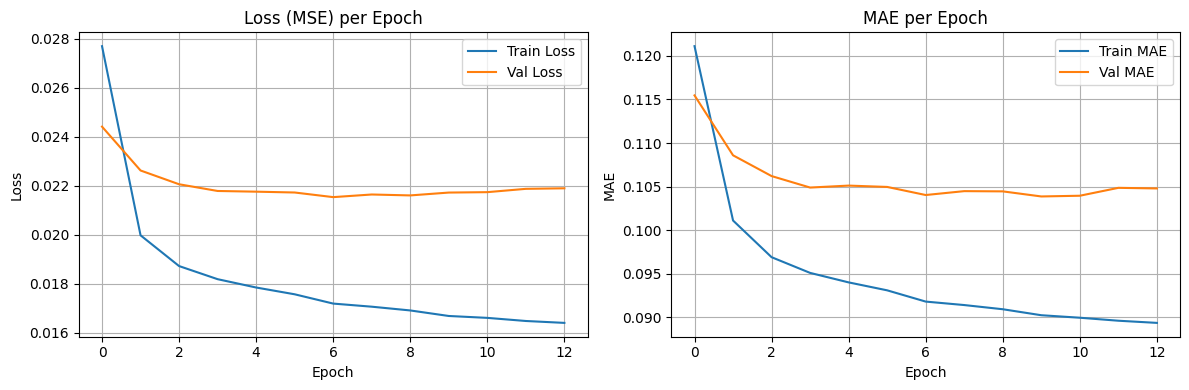

In [48]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# ============================================================
# CELL 6A — Scale the target to 0..1
# ============================================================
print("=" * 70)
print("STEP 6A: SCALE THE TARGET")
print("=" * 70)

target_scaler = MinMaxScaler()
y_train_flat = y_train.reshape(-1, 1)
target_scaler.fit(y_train_flat)

y_train_scaled = target_scaler.transform(y_train_flat).reshape(y_train.shape)
y_val_scaled = target_scaler.transform(y_val.reshape(-1, 1)).reshape(y_val.shape)

# Print min/max before and after scaling
print(f"\n[6A] Target before scaling:    {y_train.min():.1f} .. {y_train.max():.1f}")
print(f"[6A] Target after scaling :   {y_train_scaled.min():.3f} .. {y_train_scaled.max():.3f}")

# Round-trip verification check
y_train_unscaled = target_scaler.inverse_transform(y_train_scaled.reshape(-1, 1)).reshape(y_train.shape)
if np.allclose(y_train, y_train_unscaled):
    print("[6A] Round-trip check passed (scaled -> original gives the same numbers).\n")
else:
    print("[6A] Round-trip check failed!\n")

print("STEP 6A DONE")
print("=" * 70)


# ============================================================
# CELL 6B — Build the network
# ============================================================
print("\n" + "=" * 70)
print("STEP 6B: BUILD THE MODEL")
print("=" * 70)

# Fix seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

n_timesteps = X_train.shape[1]
n_features = X_train.shape[2]
n_outputs = y_train.shape[1]

model = Sequential([
    Input(shape=(n_timesteps, n_features)),
    LSTM(96, return_sequences=True),
    Dropout(0.2),
    LSTM(48, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(n_outputs)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

print(f"\n[6B] Input per sample: {n_timesteps} hours x {n_features} features\n")
print("[6B] Layers:\n")
model.summary()

print("\n[6B] `return_sequences=True` on the first LSTM passes all 24 hourly")
print("     outputs to the second LSTM. The second returns only its final")
print("     state — one summary of the whole day — which the Dense layers")
print("     turn into four AQI predictions.\n")

print("STEP 6B DONE")
print("=" * 70)


# ============================================================
# CELL 6C — Train it
# ============================================================
print("\n" + "=" * 70)
print("STEP 6C: TRAIN")
print("=" * 70)

print(f"\n[6C] Training on {X_train.shape[0]:,} samples, validating on {X_val.shape[0]:,}.")
print("     Up to 40 epochs, batch size 256.")
print("     A few minutes on a T4 GPU.\n")

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        verbose=1,
        min_lr=1e-5
    ),
    ModelCheckpoint(
        'best_lstm_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=0
    )
]

history = model.fit(
    X_train, y_train_scaled,
    validation_data=(X_val, y_val_scaled),
    epochs=40,
    batch_size=256,
    callbacks=callbacks,
    verbose=1
)

best_epoch = np.argmin(history.history['val_loss']) + 1
best_val_loss = min(history.history['val_loss'])

print(f"\n[6C] Finished after {len(history.history['loss'])} epochs.")
print(f"     Best epoch    : {best_epoch}")
print(f"     Best val_loss : {best_val_loss:.6f} (scaled units)")

print("\nSTEP 6C DONE")
print("=" * 70)


# ============================================================
# CELL 6D — Did training go well?
# ============================================================
plt.figure(figsize=(12, 4))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss (MSE) per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# MAE plot
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Val MAE')
plt.title('MAE per Epoch')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# **Task-09**

**Evaluating the model**

In [52]:
# ============================================================
# CELL 7A — Predict and Score
# ============================================================

print("=" * 70)
print("STEP 7A: LSTM PREDICTIONS")
print("=" * 70)

print("\n[7A] Predicting...")
lstm_val_pred = target_scaler.inverse_transform(
    model.predict(X_val, batch_size=512, verbose=0)
)
lstm_test_pred = target_scaler.inverse_transform(
    model.predict(X_test, batch_size=512, verbose=0)
)
print("[7A] Done — converted back to AQI units.")

lstm_val_metrics = score_model(y_val, lstm_val_pred, "LSTM VAL")
lstm_test_metrics = score_model(y_test, lstm_test_pred, "LSTM TEST")

print("\n[7A] Error grows with the horizon, which is expected — predicting")
print("     a day ahead is genuinely harder than predicting an hour ahead.")

print("\nSTEP 7A DONE")
print("=" * 70)

STEP 7A: LSTM PREDICTIONS

[7A] Predicting...
[7A] Done — converted back to AQI units.

[LSTM VAL]
  Horizon |      RMSE |       MAE |    MAPE% |      R2
--------------------------------------------------------
      +1h |    36.975 |    24.352 |    14.01 |   0.898
      +6h |    73.552 |    54.664 |    35.14 |   0.605
     +12h |    81.944 |    61.393 |    40.27 |   0.513
     +24h |    86.463 |    64.879 |    42.94 |   0.464

[LSTM TEST]
  Horizon |      RMSE |       MAE |    MAPE% |      R2
--------------------------------------------------------
      +1h |    30.104 |    20.179 |    11.48 |   0.955
      +6h |    55.087 |    38.384 |    23.39 |   0.851
     +12h |    60.333 |    41.752 |    25.37 |   0.822
     +24h |    63.503 |    44.418 |    26.16 |   0.803

[7A] Error grows with the horizon, which is expected — predicting
     a day ahead is genuinely harder than predicting an hour ahead.

STEP 7A DONE


In [53]:
# ============================================================
# CELL 7B — Health checks (read these carefully)
# ============================================================

print("=" * 70)
print("STEP 7B: HEALTH CHECKS")
print("=" * 70)

# ---- Check 1: is the model responding to its input at all? ----
print("\n[7B] Check 1 — do predictions vary?")
print(f"     {'Horizon':>9} {'pred std':>10} {'pred min':>10} {'pred max':>10} {'actual std':>11}")
is_stuck = False
for i, hours in enumerate(HORIZONS):
    pred = lstm_test_pred[:, i]
    actual = y_test[:, i]
    print(f"     {'+' + str(hours) + 'h':>9} {pred.std():10.2f} {pred.min():10.1f} "
          f"{pred.max():10.1f} {actual.std():11.2f}")
    if pred.std() < 0.05 * actual.std():
        is_stuck = True

if is_stuck:
    print("\n     WARNING: predictions barely move. The model collapsed to a")
    print("     constant and is not forecasting anything.")
else:
    print("\n     OK — predictions vary with the input.")

# ---- Check 2: are the horizons telling us different things? ----
print("\n[7B] Check 2 — do the four horizons differ from each other?")
differences = []
for i in range(len(HORIZONS)):
    for j in range(i + 1, len(HORIZONS)):
        gap = float(np.mean(np.abs(lstm_test_pred[:, i] - lstm_test_pred[:, j])))
        differences.append(gap)
        print(f"     +{HORIZONS[i]}h vs +{HORIZONS[j]}h : {gap:7.2f} AQI apart on average")

actual_gap = float(np.mean(np.abs(y_test[:, 0] - y_test[:, -1])))
print(f"\n     average across all pairs : {np.mean(differences):.2f}")
print(f"     the same figure for real data : {actual_gap:.2f}")

if np.mean(differences) < 0.1 * actual_gap:
    print("\n     WARNING: the horizons collapsed — the model emits one number")
    print("     four times over, so '+24h' carries no extra information.")
else:
    print("\n     OK — the horizons are genuinely different predictions.")

print("\nSTEP 7B DONE")
print("=" * 70)

STEP 7B: HEALTH CHECKS

[7B] Check 1 — do predictions vary?
       Horizon   pred std   pred min   pred max  actual std
           +1h     131.32       11.1      519.5      141.14
           +6h     126.24       24.4      519.2      142.89
          +12h     125.61       39.0      499.8      142.97
          +24h     123.01       42.3      476.6      143.25

     OK — predictions vary with the input.

[7B] Check 2 — do the four horizons differ from each other?
     +1h vs +6h :   32.84 AQI apart on average
     +1h vs +12h :   38.20 AQI apart on average
     +1h vs +24h :   22.00 AQI apart on average
     +6h vs +12h :   34.72 AQI apart on average
     +6h vs +24h :   38.50 AQI apart on average
     +12h vs +24h :   34.63 AQI apart on average

     average across all pairs : 33.48
     the same figure for real data : 47.91

     OK — the horizons are genuinely different predictions.

STEP 7B DONE


In [55]:
# ============================================================
# CELL 7C — The scoreboard
# ============================================================
# Everything comes down to this table. Lower RMSE wins.
#
# Expect persistence to be strong at +1h — air quality doesn't
# change much in an hour, so "no change" is a good guess. The
# horizons that matter for warning people and planning routes
# are +12h and +24h, and that is where a real forecaster should
# pull clearly ahead.

print("=" * 70)
print("STEP 7C: MODEL COMPARISON (TEST SET)")
print("=" * 70)

print(f"\nTest period : {pd.Timestamp(end_test.min())}  ->  {pd.Timestamp(end_test.max())}")
print(f"Test samples: {len(y_test):,}\n")

print(f"{'Horizon':>9} | {'Persist':>10} | {'Ridge':>10} | {'LSTM':>10} | "
      f"{'Winner':>11} | {'LSTM gain':>10}")
print("-" * 78)

comparison_rows = []
for i, hours in enumerate(HORIZONS):
    persist_rmse = persist_test_metrics[i]["rmse"]
    ridge_rmse = ridge_test_metrics[i]["rmse"]
    lstm_rmse = lstm_test_metrics[i]["rmse"]

    scores = {"Persistence": persist_rmse, "Ridge": ridge_rmse, "LSTM": lstm_rmse}
    winner = min(scores, key=scores.get)

    best_baseline = min(persist_rmse, ridge_rmse)
    gain = 100 * (best_baseline - lstm_rmse) / best_baseline

    print(f"{'+' + str(hours) + 'h':>9} | {persist_rmse:10.3f} | {ridge_rmse:10.3f} | "
          f"{lstm_rmse:10.3f} | {winner:>11} | {gain:+9.1f}%")

    comparison_rows.append(
        {
            "horizon_h": hours,
            "persistence_rmse": persist_rmse,
            "ridge_rmse": ridge_rmse,
            "lstm_rmse": lstm_rmse,
            "lstm_mae": lstm_test_metrics[i]["mae"],
            "lstm_r2": lstm_test_metrics[i]["r2"],
            "winner_rmse": winner,
            "lstm_gain_pct_vs_best_baseline": gain,
        }
    )

print("\n(RMSE in AQI points. 'LSTM gain' is against whichever baseline did better.)")

beats_ridge = all(r["lstm_rmse"] < r["ridge_rmse"] for r in comparison_rows)
beats_persistence_long = comparison_rows[-1]["lstm_rmse"] < comparison_rows[-1]["persistence_rmse"]

print("\n[7C] Did it work?")
print(f"     Beats Ridge on every horizon    : {beats_ridge}")
print(f"     Beats persistence at +{HORIZONS[-1]}h        : {beats_persistence_long}")

if beats_ridge and beats_persistence_long:
    verdict = "PASS — the LSTM adds real forecasting value"
elif beats_ridge:
    verdict = "PARTIAL — beats Ridge, but not persistence at long range"
else:
    verdict = "NOT YET — a linear model is still competitive"
print(f"\n     RESULT: {verdict}")

print("\nSTEP 7C DONE")
print("=" * 70)

STEP 7C: MODEL COMPARISON (TEST SET)

Test period : 2023-07-01 04:00:00  ->  2023-12-31 04:00:00
Test samples: 19,465

  Horizon |    Persist |      Ridge |       LSTM |      Winner |  LSTM gain
------------------------------------------------------------------------------
      +1h |     32.935 |     31.482 |     30.104 |        LSTM |      +4.4%
      +6h |     88.625 |     76.427 |     55.087 |        LSTM |     +27.9%
     +12h |     95.826 |     79.073 |     60.333 |        LSTM |     +23.7%
     +24h |     71.106 |     67.410 |     63.503 |        LSTM |      +5.8%

(RMSE in AQI points. 'LSTM gain' is against whichever baseline did better.)

[7C] Did it work?
     Beats Ridge on every horizon    : True
     Beats persistence at +24h        : True

     RESULT: PASS — the LSTM adds real forecasting value

STEP 7C DONE


In [57]:
# ============================================================
# CELL 7D — Error station by station
# ============================================================

print("=" * 70)
print("STEP 7D: ERROR BY STATION")
print("=" * 70)

print(f"\n[7D] Test-set accuracy at +{HORIZONS[0]}h\n")
print(f"     {'Station':42} {'N':>7} {'RMSE':>8} {'MAE':>8} {'actual':>8} {'pred':>8}")
print("     " + "-" * 84)

station_report = []
for name in sorted(np.unique(station_test)):
    pick = station_test == name
    actual = y_test[pick, 0]
    predicted = lstm_test_pred[pick, 0]

    rmse = float(np.sqrt(mean_squared_error(actual, predicted)))
    mae = float(mean_absolute_error(actual, predicted))

    print(f"     {name[:42]:42} {int(pick.sum()):7,} {rmse:8.2f} {mae:8.2f} "
          f"{actual.mean():8.1f} {predicted.mean():8.1f}")
    station_report.append(
        {"station": name, "n": int(pick.sum()), "rmse": rmse, "mae": mae}
    )

bias = float(np.mean(lstm_test_pred[:, 0] - y_test[:, 0]))
print(f"\n[7D] Average bias across all stations: {bias:+.1f} AQI points")
if bias < -10:
    print("     The model under-predicts. For an alert system that means")
    print("     occasionally telling people the air is safer than it is.")
elif bias > 10:
    print("     The model over-predicts, so alerts will fire a little early.")
else:
    print("     Close to zero — no strong systematic bias.")

print("\nSTEP 7D DONE")
print("=" * 70)

STEP 7D: ERROR BY STATION

[7D] Test-set accuracy at +1h

     Station                                          N     RMSE      MAE   actual     pred
     ------------------------------------------------------------------------------------
     Alipur, Delhi - DPCC                           529    24.31    18.09    204.3    193.8
     Anand Vihar, Delhi - DPCC                      275    38.77    27.53    312.0    297.5
     Ashok Vihar, Delhi - DPCC                      412    27.28    18.98    239.0    230.4
     Aya Nagar, Delhi - IMD                         489    41.11    26.99    207.5    199.9
     Bawana, Delhi - DPCC                           629    27.03    19.37    244.7    235.3
     CRRI Mathura Road, Delhi - IMD                 546    31.33    22.26    213.0    202.3
     DTU, Delhi - CPCB                              491    32.59    20.56    186.6    183.8
     Dr. Karni Singh Shooting Range, Delhi - DP     593    25.10    18.01    215.2    205.8
     Dwarka-Sector 8, De

STEP 7E: PREDICTIONS OVER TIME

[7E] Showing Alipur, Delhi - DPCC (400 consecutive test windows)


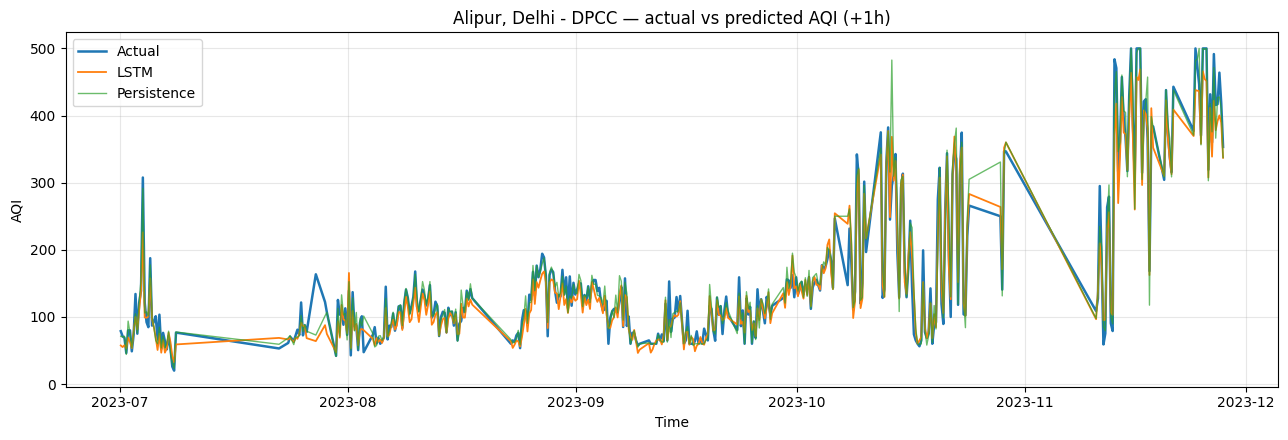

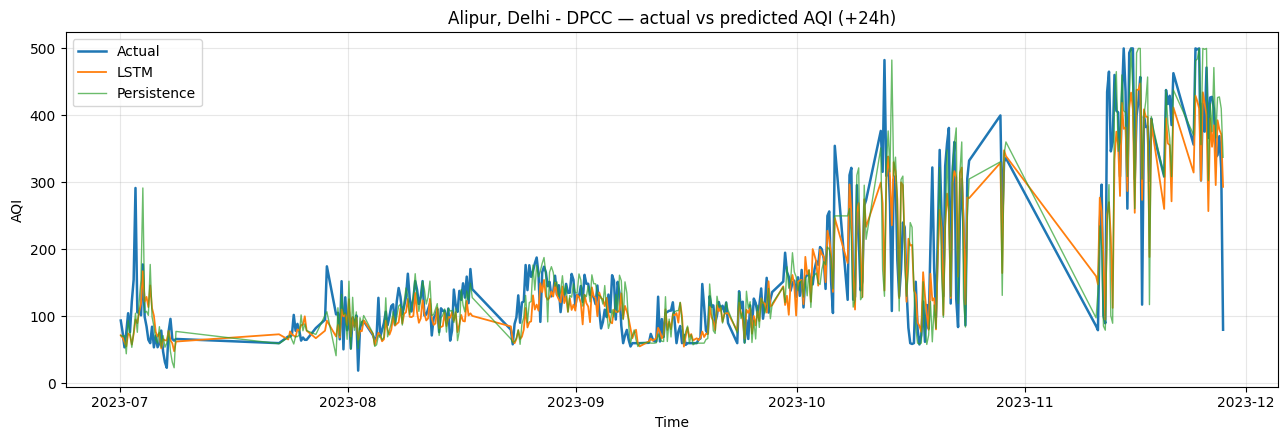


[7E] Compare the two charts. At +1h everything tracks closely.
     At +24h the persistence line visibly lags the real one,
     and that lag is the gap the LSTM is trying to close.

STEP 7E DONE


In [58]:
# ============================================================
# CELL 7E — Plot: predicted vs actual over time
# ============================================================
print("=" * 70)
print("STEP 7E: PREDICTIONS OVER TIME")
print("=" * 70)

focus_station = sorted(np.unique(station_test))[0]
pick = station_test == focus_station

# Sort by time so the line joins up in the right order.
order = np.argsort(end_test[pick])[:400]
time_axis = pd.to_datetime(end_test[pick][order])

print(f"\n[7E] Showing {focus_station} ({len(order)} consecutive test windows)")

for horizon_index, hours in ((0, HORIZONS[0]), (len(HORIZONS) - 1, HORIZONS[-1])):
    plt.figure(figsize=(13, 4.5))
    plt.plot(time_axis, y_test[pick][order, horizon_index],
             label="Actual", linewidth=1.8)
    plt.plot(time_axis, lstm_test_pred[pick][order, horizon_index],
             label="LSTM", linewidth=1.3)
    plt.plot(time_axis, persist_test_pred[pick][order, horizon_index],
             label="Persistence", linewidth=1.0, alpha=0.7)
    plt.title(f"{focus_station} — actual vs predicted AQI (+{hours}h)")
    plt.xlabel("Time")
    plt.ylabel("AQI")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

print("\n[7E] Compare the two charts. At +1h everything tracks closely.")
print(f"     At +{HORIZONS[-1]}h the persistence line visibly lags the real one,")
print("     and that lag is the gap the LSTM is trying to close.")

print("\nSTEP 7E DONE")
print("=" * 70)

STEP 7F: SCATTER AND RESIDUALS

[7F] Predicted vs actual (a sample of test points)


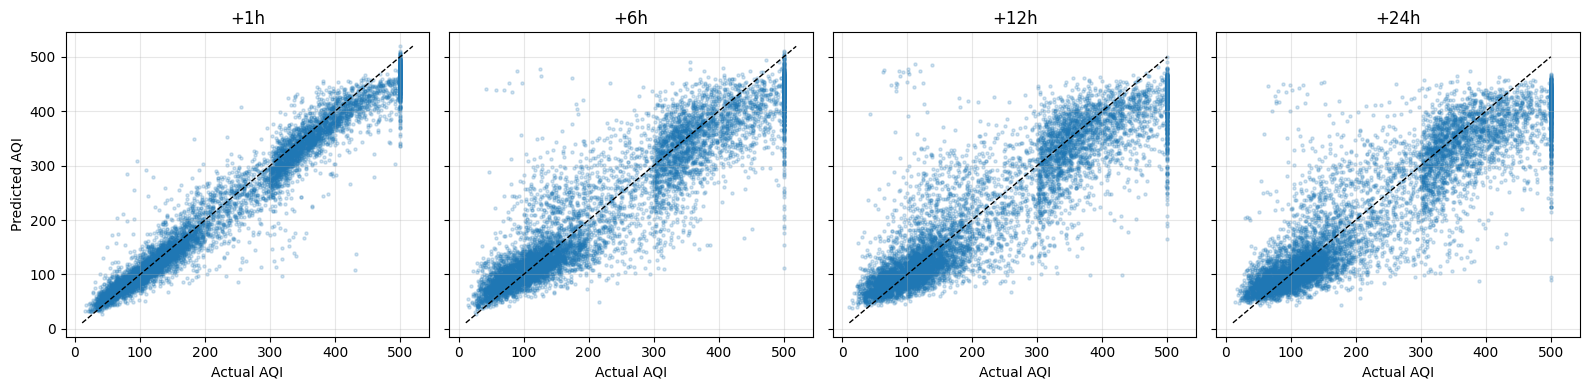


[7F] Residuals (actual minus predicted)


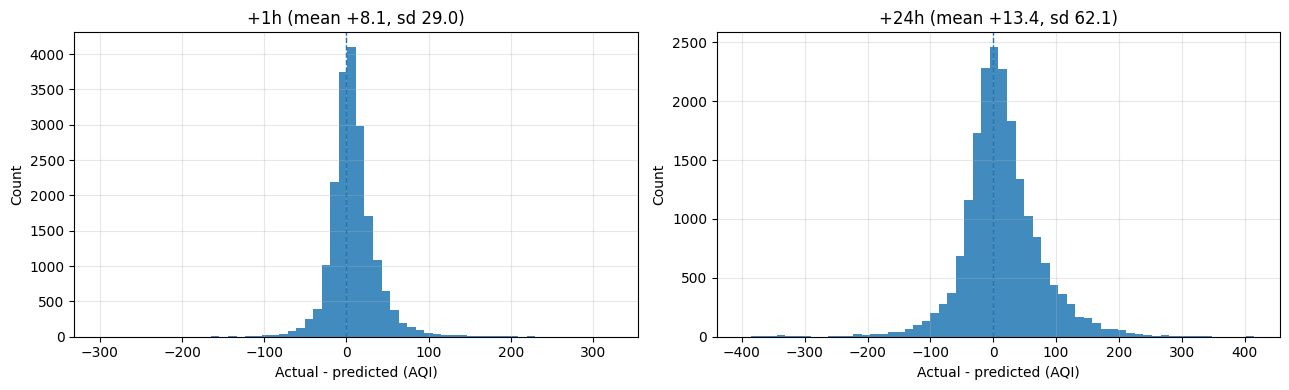


[7F] Notice the scatter cloud widening as the horizon grows.
     That widening IS the uncertainty of forecasting further ahead.

STEP 7F DONE


In [59]:
# ============================================================
# CELL 7F — Scatter and Residuals
# ============================================================

# Scatter: every point is one prediction.The dashed diagonal is a perfect forecast.
#
# Residuals: actual minus predicted.A residual distribution centred around zero
# indicates little systematic bias.

print("=" * 70)
print("STEP 7F: SCATTER AND RESIDUALS")
print("=" * 70)

# ------------------------------------------------------------
# Take a sample of test points for the scatter plots
# ------------------------------------------------------------

rng = np.random.default_rng(RANDOM_SEED)

sample = rng.choice(
    len(y_test),
    size=min(8000, len(y_test)),
    replace=False
)


# ============================================================
# PART 1 — PREDICTED VS ACTUAL
# ============================================================

print("\n[7F] Predicted vs actual (a sample of test points)")

fig, axes = plt.subplots(
    1,
    len(HORIZONS),
    figsize=(4 * len(HORIZONS), 4),
    sharex=True,
    sharey=True
)

for i, hours in enumerate(HORIZONS):

    ax = axes[i]

    # YOUR LSTM predictions
    ax.scatter(
        y_test[sample, i],
        y_pred_lstm_test[sample, i],
        s=5,
        alpha=0.2
    )

    # Perfect prediction line
    low = float(
        min(
            y_test[:, i].min(),
            y_pred_lstm_test[:, i].min()
        )
    )

    high = float(
        max(
            y_test[:, i].max(),
            y_pred_lstm_test[:, i].max()
        )
    )

    ax.plot(
        [low, high],
        [low, high],
        "k--",
        linewidth=1
    )

    ax.set_title(
        f"+{hours}h"
    )

    ax.set_xlabel("Actual AQI")

    ax.grid(
        True,
        alpha=0.3
    )

axes[0].set_ylabel("Predicted AQI")

plt.tight_layout()
plt.show()


# ============================================================
# PART 2 — RESIDUALS
# ============================================================

print("\n[7F] Residuals (actual minus predicted)")

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4)
)

# +1h and +24h
for slot, i in enumerate(
    (0, len(HORIZONS) - 1)
):

    # Actual - predicted
    residuals = (
        y_test[:, i]
        - y_pred_lstm_test[:, i]
    )

    ax = axes[slot]

    ax.hist(
        residuals,
        bins=60,
        alpha=0.85
    )

    # Zero-error reference line
    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"+{HORIZONS[i]}h "
        f"(mean {residuals.mean():+.1f}, "
        f"sd {residuals.std():.1f})"
    )

    ax.set_xlabel(
        "Actual - predicted (AQI)"
    )

    ax.set_ylabel("Count")

    ax.grid(
        True,
        alpha=0.3
    )

plt.tight_layout()
plt.show()


# ============================================================
# FINAL MESSAGE
# ============================================================

print(
    "\n[7F] Notice the scatter cloud widening as the horizon grows."
)

print(
    "     That widening IS the uncertainty of forecasting further ahead."
)

print("\nSTEP 7F DONE")
print("=" * 70)

# **Saving the files**

In [64]:
# ============================================================
# CELL 8A — Save the model and both scalers
# ============================================================
print("=" * 70)
print("STEP 8A: SAVE MODEL + SCALERS")
print("=" * 70)

# Your VayuMarg model directory
MODEL_DIR = Path("/content/drive/MyDrive/Datasets_Assignment") / "VayuMarg" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "aqi_lstm.keras"
scaler_path = MODEL_DIR / "scaler.pkl"
target_scaler_path = MODEL_DIR / "target_scaler.pkl"

# Save trained LSTM
model.save(model_path)
print(f"\n[8A] Model          -> {model_path}")

# Save feature scaler
joblib.dump(scaler, scaler_path)
print(f"[8A] Feature scaler -> {scaler_path}")

# Save target scaler
joblib.dump(target_scaler, target_scaler_path)
print(f"[8A] Target scaler  -> {target_scaler_path}")

print("\nSTEP 8A DONE")
print("=" * 70)

STEP 8A: SAVE MODEL + SCALERS

[8A] Model          -> /content/drive/MyDrive/Datasets_Assignment/VayuMarg/models/aqi_lstm.keras
[8A] Feature scaler -> /content/drive/MyDrive/Datasets_Assignment/VayuMarg/models/scaler.pkl
[8A] Target scaler  -> /content/drive/MyDrive/Datasets_Assignment/VayuMarg/models/target_scaler.pkl

STEP 8A DONE


In [66]:
# ============================================================
# CELL 8B — Save the config and the metrics
# ============================================================
import json

print("=" * 70)
print("STEP 8B: SAVE CONFIG + METRICS")
print("=" * 70)

# ------------------------------------------------------------
# Feature configuration
# ------------------------------------------------------------

feature_config = {
    "feature_cols": FEATURE_COLS,
    "pollutant_cols": POLLUTANT_COLS,
    "target_col": TARGET_COL,
    "n_features": len(FEATURE_COLS),

    "model_file": "aqi_lstm.keras",
    "scaler_file": "scaler.pkl",
    "target_scaler_file": "target_scaler.pkl",

    "inference_note": (
        "Scale features with scaler.pkl using the saved feature "
        "order, run the LSTM model, then use target_scaler.inverse_transform() "
        "to convert the output back to AQI."
    ),
}

config_path = MODEL_DIR / "feature_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(feature_config, f, indent=2)

print(f"\n[8B] Config  -> {config_path}")

# ------------------------------------------------------------
# Model metrics
# ------------------------------------------------------------

metrics = {
    "lstm_val": lstm_val_metrics,
    "lstm_test": lstm_test_metrics,
}

# Add comparison results if they exist
if "comparison_rows" in globals():
    metrics["comparison_test"] = comparison_rows

# Add station report if it exists
if "station_report" in globals():
    metrics["per_station_test"] = station_report

# Dataset/sample information
metrics["n_train"] = int(len(X_train))
metrics["n_val"] = int(len(X_val))
metrics["n_test"] = int(len(X_test))

metrics_path = MODEL_DIR / "metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, default=str)

print(f"[8B] Metrics -> {metrics_path}")

print("\nSTEP 8B DONE")
print("=" * 70)

STEP 8B: SAVE CONFIG + METRICS

[8B] Config  -> /content/drive/MyDrive/Datasets_Assignment/VayuMarg/models/feature_config.json
[8B] Metrics -> /content/drive/MyDrive/Datasets_Assignment/VayuMarg/models/metrics.json

STEP 8B DONE


In [69]:
# ============================================================
# CELL 8C — Write a report you can hand in
# ============================================================

print("=" * 70)
print("STEP 8C: WRITE THE REPORT")
print("=" * 70)

report = [
    "# VayuMarg Bangalore AQI LSTM — Training Report",
    "",

    "## Data",
    "- Source: CPCB CAAQMS pollutant readings (real government sensors)",
    "- Retrieved from: github.com/Vonter/india-cpcb-aqi yearly releases",
    f"- Years: {YEARS[0]}-{YEARS[-1]}",
    f"- Stations: {len(good_stations)} across Delhi",
    f"- Pollutants: {', '.join(POLLUTANT_COLS)}",
    f"- Period: {data_start.date()} to {data_end.date()}",
    f"- Samples: train {len(X_train):,} / val {len(X_val):,} / test {len(X_test):,}",
    f"- Train: window ends on or before {TRAIN_END.date()}",
    f"- Validation: {VAL_START.date()} to {VAL_END.date()}",
    f"- Test: {TEST_START.date()} onwards",
    "- Target: CPCB AQI = max sub-index of PM2.5, PM10, NO2, CO, O3",
    "",

    "## Model",
    f"- Input: {LOOKBACK} hours x {len(FEATURE_COLS)} features",
    f"- Output: AQI at {', '.join('+' + str(h) + 'h' for h in HORIZONS)}",
    "- LSTM model trained using scaled input features",
    f"- New window every {STRIDE} hours",
    "- Target scaled to 0-1 for training; all metrics below are in AQI points",
    "",

    "## Test results (RMSE in AQI points, lower is better)",
    "",
    "| Horizon | RMSE | MAE | R2 |",
    "|---|---|---|---|",
]

# Add LSTM test metrics
for row in lstm_test_metrics:
    report.append(
        f"| +{row['horizon_h']}h | "
        f"{row['rmse']:.2f} | "
        f"{row['mae']:.2f} | "
        f"{row['r2']:.3f} |"
    )

report += [
    "",

    "## Saved model files",
    "- aqi_lstm.keras — trained LSTM model",
    "- scaler.pkl — feature scaler",
    "- target_scaler.pkl — target/AQI scaler",
    "- feature_config.json — model feature configuration",
    "- metrics.json — model evaluation metrics",
    "- training_report.md — training and evaluation report",
    "",

    "## Known limits",
    "- Real sensor data can contain missing observations.",
    "- Windows requiring unavailable data may be skipped during preprocessing.",
    "- The feature order must remain unchanged during inference.",
    "- The target scaler must be used to convert model output back to AQI.",
    "- Future versions can incorporate additional weather and traffic information.",
    "",
]

# ------------------------------------------------------------
# Save report
# ------------------------------------------------------------

report_path = MODEL_DIR / "training_report.md"

with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(report))

print(f"\n[8C] Report -> {report_path}")

print("\n[8C] Preview:\n")
print("\n".join(report[:25]))

print("\nSTEP 8C DONE")
print("=" * 70)

STEP 8C: WRITE THE REPORT

[8C] Report -> /content/drive/MyDrive/Datasets_Assignment/VayuMarg/models/training_report.md

[8C] Preview:

# VayuMarg Bangalore AQI LSTM — Training Report

## Data
- Source: CPCB CAAQMS pollutant readings (real government sensors)
- Retrieved from: github.com/Vonter/india-cpcb-aqi yearly releases
- Years: 2019-2023
- Stations: 36 across Delhi
- Pollutants: pm25, pm10, no2, co, o3
- Period: 2019-01-01 to 2024-01-01
- Samples: train 153,199 / val 20,687 / test 19,465
- Train: window ends on or before 2022-12-31
- Validation: 2023-01-01 to 2023-06-30
- Test: 2023-07-01 onwards
- Target: CPCB AQI = max sub-index of PM2.5, PM10, NO2, CO, O3

## Model
- Input: 24 hours x 48 features
- Output: AQI at +1h, +6h, +12h, +24h
- LSTM model trained using scaled input features
- New window every 6 hours
- Target scaled to 0-1 for training; all metrics below are in AQI points

## Test results (RMSE in AQI points, lower is better)

| Horizon | RMSE | MAE | R2 |

STEP 8C DON

In [72]:
# ============================================================
# CELL 8D — Reload everything and prove it works
# ============================================================
print("=" * 70)
print("STEP 8D: RELOAD TEST")
print("=" * 70)

print("\n[8D] Loading from Drive...")

# Load saved files
loaded_model = tf.keras.models.load_model(model_path)
loaded_scaler = joblib.load(scaler_path)
loaded_target_scaler = joblib.load(target_scaler_path)

with open(config_path, encoding="utf-8") as f:
    loaded_config = json.load(f)

print("     Loaded.")

# ------------------------------------------------------------
# Shape / feature check
# ------------------------------------------------------------

if loaded_config["n_features"] != X_test.shape[-1]:
    raise RuntimeError(
        "Saved feature count does not match the test data."
    )

print(
    f"     Shape check OK: model input has "
    f"{loaded_config['n_features']} features"
)

# ------------------------------------------------------------
# Make predictions using reloaded model
# ------------------------------------------------------------

reload_predictions = loaded_model.predict(
    X_test[:5],
    verbose=0
)

# Convert predictions back to AQI
reload_predictions_aqi = loaded_target_scaler.inverse_transform(
    reload_predictions
)

# ------------------------------------------------------------
# Original predictions for comparison
# ------------------------------------------------------------

original_predictions = model.predict(
    X_test[:5],
    verbose=0
)

original_predictions_aqi = target_scaler.inverse_transform(
    original_predictions
)

# ------------------------------------------------------------
# Check whether saved model gives same predictions
# ------------------------------------------------------------

if np.allclose(
    original_predictions_aqi,
    reload_predictions_aqi,
    rtol=1e-5,
    atol=1e-5
):
    print("\n     PASSED — the reloaded model gives the same answers.")
else:
    raise RuntimeError(
        "FAILED — reloaded model predictions do not match "
        "the original model."
    )

# ------------------------------------------------------------
# Display predictions
# ------------------------------------------------------------

print("\n[8D] Predictions for 5 test windows (AQI):")

print("\n     Reloaded predictions:")
print(reload_predictions_aqi)

# ------------------------------------------------------------
# List saved files
# ------------------------------------------------------------

print("\n[8D] Files saved to Drive:")

for file_path in sorted(MODEL_DIR.iterdir()):
    if file_path.is_file():
        size_kb = file_path.stat().st_size / 1024
        print(f"     {file_path.name:<28} {size_kb:.1f} KB")

print("\n" + "=" * 70)
print("ALL DONE")
print("VayuMarg files saved to:")
print(f"{MODEL_DIR}")
print("=" * 70)

STEP 8D: RELOAD TEST

[8D] Loading from Drive...
     Loaded.
     Shape check OK: model input has 48 features

     PASSED — the reloaded model gives the same answers.

[8D] Predictions for 5 test windows (AQI):

     Reloaded predictions:
[[57.481014 65.039444 55.400433 71.83143 ]
 [55.079216 69.18134  53.46575  67.95379 ]
 [57.82642  69.0995   79.21936  61.837383]
 [53.077515 69.416115 66.96766  55.227505]
 [69.08059  76.56266  66.934074 74.42918 ]]

[8D] Files saved to Drive:
     aqi_lstm.keras               1039.6 KB
     feature_config.json          2.1 KB
     metrics.json                 7.6 KB
     scaler.pkl                   4.1 KB
     target_scaler.pkl            0.7 KB
     training_report.md           1.6 KB

ALL DONE
VayuMarg files saved to:
/content/drive/MyDrive/Datasets_Assignment/VayuMarg/models
